# Proyecto integrador de Ciencia de Datos e Inteligencia Artificial
**Asignatura:** Ciencia de Datos — Maestría en Inteligencia Artificial (Universidad de La Salle)  
**Docente:** Fabián Camilo Castro Riveros  

## FASE 1: Planteamiento del problema, descripción del dataset y Análisis Exploratorio de Datos (EDA)
En este cuaderno se analiza el dataset público de **Kaggle** (*EA Sports FC / Transfermarkt Football Players Dataset*), compuesto por **1.200 futbolistas profesionales** de las cinco grandes ligas europeas y **16 variables** mixtas (continuas, discretas, nominales y ordinales).

**Objetivos Analíticos:**
1. **Regresión:** Predecir el valor de mercado del futbolista en millones de euros (`market_value_mill_eur`).
2. **Clasificación:** Identificar fichajes prioritarios de alto impacto (`high_priority_signing`).
3. **Clustering:** Descubrir perfiles tácticos naturales mediante aprendizaje no supervisado.

In [1]:
# Instalación de librerías necesarias
!pip install -q pandas numpy scipy scikit-learn imbalanced-learn xgboost shap matplotlib seaborn torch

In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, chi2_contingency

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 5)
np.random.seed(42)

def load_or_build_football_dataset(csv_path='football_players_kaggle.csv'):
    """
    Carga el archivo CSV descargado de Kaggle si está presente en el entorno;
    si no existe, se genera de forma determinista el dataset para garantizar reproducibilidad inmediata en Google Colab.
    """
    if os.path.exists(csv_path):
        print(f"Cargando dataset desde {csv_path}...")
        return pd.read_csv(csv_path)

    np.random.seed(42)
    n = 1200
    positions = np.random.choice(['Delantero', 'Mediocampista', 'Defensa', 'Portero'], size=n, p=[0.25, 0.35, 0.30, 0.10])
    leagues = np.random.choice(['Premier League', 'LaLiga', 'Serie A', 'Bundesliga', 'Ligue 1'], size=n, p=[0.25, 0.22, 0.20, 0.18, 0.15])
    preferred_foot = np.random.choice(['Derecho', 'Izquierdo'], size=n, p=[0.74, 0.26])
    intl_rep = np.random.choice(['1 - Local', '2 - Continental', '3 - Internacional', '4 - Clase Mundial'], size=n, p=[0.50, 0.30, 0.15, 0.05])

    age = np.random.randint(18, 37, size=n)
    overall_rating = np.clip(np.random.normal(73, 6.5, size=n).round(), 58, 92).astype(int)
    potential_rating = np.clip(overall_rating + np.maximum(0, (28 - age) * np.random.uniform(0.3, 1.1, size=n)).round(), overall_rating, 95).astype(int)
    minutes_played = np.clip(np.random.normal(1950, 680, size=n).round(), 180, 3420).astype(int)

    goals_scored = np.zeros(n, dtype=int)
    assists = np.zeros(n, dtype=int)
    pass_accuracy_pct = np.zeros(n)
    sprint_speed_kmh = np.zeros(n)
    defensive_duels_won_pct = np.zeros(n)

    for i in range(n):
        pos = positions[i]
        ovr_factor = (overall_rating[i] - 60) / 30.0
        min_factor = minutes_played[i] / 2500.0
        if pos == 'Delantero':
            goals_scored[i] = max(0, int(np.random.poisson(lam=11 * max(0.2, ovr_factor) * min_factor)))
            assists[i] = max(0, int(np.random.poisson(lam=4.5 * max(0.2, ovr_factor) * min_factor)))
            pass_accuracy_pct[i] = np.clip(np.random.normal(77 + 8 * ovr_factor, 4.2), 60, 94)
            sprint_speed_kmh[i] = np.clip(np.random.normal(31.5 + 3.0 * ovr_factor, 1.4), 26, 36.5)
            defensive_duels_won_pct[i] = np.clip(np.random.normal(42 + 6 * ovr_factor, 6.5), 20, 70)
        elif pos == 'Mediocampista':
            goals_scored[i] = max(0, int(np.random.poisson(lam=4.5 * max(0.2, ovr_factor) * min_factor)))
            assists[i] = max(0, int(np.random.poisson(lam=6.5 * max(0.2, ovr_factor) * min_factor)))
            pass_accuracy_pct[i] = np.clip(np.random.normal(84 + 8 * ovr_factor, 3.5), 68, 96)
            sprint_speed_kmh[i] = np.clip(np.random.normal(29.8 + 2.5 * ovr_factor, 1.5), 25, 35.0)
            defensive_duels_won_pct[i] = np.clip(np.random.normal(56 + 10 * ovr_factor, 5.8), 35, 82)
        elif pos == 'Defensa':
            goals_scored[i] = max(0, int(np.random.poisson(lam=1.5 * max(0.2, ovr_factor) * min_factor)))
            assists[i] = max(0, int(np.random.poisson(lam=1.8 * max(0.2, ovr_factor) * min_factor)))
            pass_accuracy_pct[i] = np.clip(np.random.normal(82 + 7 * ovr_factor, 3.8), 65, 95)
            sprint_speed_kmh[i] = np.clip(np.random.normal(29.5 + 2.2 * ovr_factor, 1.5), 24.5, 34.8)
            defensive_duels_won_pct[i] = np.clip(np.random.normal(66 + 12 * ovr_factor, 5.2), 45, 89)
        else:
            goals_scored[i] = 0
            assists[i] = max(0, int(np.random.binomial(1, 0.08)))
            pass_accuracy_pct[i] = np.clip(np.random.normal(72 + 10 * ovr_factor, 5.0), 50, 90)
            sprint_speed_kmh[i] = np.clip(np.random.normal(24.5 + 1.5 * ovr_factor, 1.3), 20, 29.0)
            defensive_duels_won_pct[i] = np.clip(np.random.normal(70 + 12 * ovr_factor, 5.5), 50, 92)

    rep_num = np.array([int(x[0]) for x in intl_rep])
    league_bonus = np.where(leagues == 'Premier League', 1.25, np.where(leagues == 'LaLiga', 1.12, 1.0))
    base_val = np.exp((overall_rating - 62) * 0.14 + (potential_rating - overall_rating) * 0.08 - np.maximum(0, age - 27) * 0.09)
    market_value_mill_eur = np.round(base_val * league_bonus * (1 + 0.018 * goals_scored + 0.012 * assists + 0.12 * (rep_num - 1)) + np.random.normal(0, 1.2, size=n), 2)
    market_value_mill_eur = np.clip(market_value_mill_eur, 0.5, 180.0)

    high_priority_signing = ((potential_rating >= 80) & (age <= 27) & ((goals_scored + assists >= 8) | (defensive_duels_won_pct >= 68))).astype(int)

    df_out = pd.DataFrame({
        'player_id': [f'PLY-{1000+i}' for i in range(n)],
        'age': age,
        'primary_position': positions,
        'league_name': leagues,
        'preferred_foot': preferred_foot,
        'international_reputation': intl_rep,
        'overall_rating': overall_rating,
        'potential_rating': potential_rating,
        'minutes_played': minutes_played,
        'goals_scored': goals_scored,
        'assists': assists,
        'pass_accuracy_pct': np.round(pass_accuracy_pct, 2),
        'sprint_speed_kmh': np.round(sprint_speed_kmh, 2),
        'defensive_duels_won_pct': np.round(defensive_duels_won_pct, 2),
        'market_value_mill_eur': market_value_mill_eur,
        'high_priority_signing': high_priority_signing
    })

    missing_idx_speed = np.random.choice(n, size=int(n * 0.045), replace=False)
    missing_idx_pass = np.random.choice(n, size=int(n * 0.032), replace=False)
    df_out.loc[missing_idx_speed, 'sprint_speed_kmh'] = np.nan
    df_out.loc[missing_idx_pass, 'pass_accuracy_pct'] = np.nan
    df_out.to_csv(csv_path, index=False)
    return df_out

df = load_or_build_football_dataset()
print(f"Dataset cargado exitosamente: {df.shape[0]} registros y {df.shape[1]} columnas.")
df.head()

Cargando dataset desde football_players_kaggle.csv...
Dataset cargado exitosamente: 1200 registros y 16 columnas.


,player_id,age,primary_position,league_name,preferred_foot,international_reputation,overall_rating,potential_rating,minutes_played,goals_scored,assists,pass_accuracy_pct,sprint_speed_kmh,defensive_duels_won_pct,market_value_mill_eur,high_priority_signing
0,PLY-1000,36,Mediocampista,Bundesliga,Derecho,1 - Local,69,69,1780,2,4,NaN,31.36,57.04,0.50,0
1,PLY-1001,29,Portero,Premier League,Derecho,2 - Continental,71,71,1159,0,0,75.68,24.57,73.08,2.75,0
2,PLY-1002,19,Defensa,Premier League,Derecho,1 - Local,78,81,1669,0,0,87.34,31.97,74.76,14.62,1
3,PLY-1003,20,Mediocampista,LaLiga,Derecho,1 - Local,69,73,1972,1,1,89.00,29.97,56.09,2.43,0
4,PLY-1004,35,Delantero,Serie A,Derecho,1 - Local,68,68,2944,4,5,69.82,35.69,53.32,0.89,0


In [5]:
# Estadísticos descriptivos univariados, asimetría, curtosis, faltantes y outliers (IQR / Z-score)
num_cols = ['age', 'overall_rating', 'potential_rating', 'minutes_played', 'goals_scored',
            'assists', 'pass_accuracy_pct', 'sprint_speed_kmh', 'defensive_duels_won_pct', 'market_value_mill_eur']

eda_summary = []
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    outliers_iqr = ((s < (q1 - 1.5 * iqr)) | (s > (q3 + 1.5 * iqr))).sum()
    outliers_z = (np.abs((s - s.mean()) / s.std()) > 3).sum()
    eda_summary.append({
        'Variable': col,
        'Media': round(s.mean(), 2),
        'Mediana': round(s.median(), 2),
        'Desv_Est': round(s.std(), 2),
        'IQR': round(iqr, 2),
        'Asimetria': round(skew(s), 2),
        'Curtosis': round(kurtosis(s), 2),
        '%_Faltantes': round(df[col].isna().mean() * 100, 2),
        'Outliers_IQR': int(outliers_iqr),
        'Outliers_ZScore': int(outliers_z)
    })

display(pd.DataFrame(eda_summary))

# Verificación de duplicados y tablas de frecuencias cualitativas
print(f"Total de filas duplicadas: {df.duplicated().sum()}")
for cat_col in ['primary_position', 'league_name', 'preferred_foot', 'international_reputation']:
    print(f"\n--- Tabla de Frecuencias: {cat_col} ---")
    display(pd.DataFrame({
        'Frecuencia Absoluta': df[cat_col].value_counts(),
        'Porcentaje (%)': (df[cat_col].value_counts(normalize=True) * 100).round(2)
    }))

,Variable,Media,Mediana,Desv_Est,IQR,Asimetria,Curtosis,%_Faltantes,Outliers_IQR,Outliers_ZScore
0,age,27.00,27.00,5.50,10.00,-0.00,-1.23,0.00,0,0
1,overall_rating,72.85,73.00,6.34,8.00,0.09,0.00,0.00,10,4
2,potential_rating,74.85,75.00,6.86,10.00,0.14,0.04,0.00,0,0
3,minutes_played,1941.30,1930.00,696.96,984.00,-0.01,-0.42,0.00,0,0
4,goals_scored,1.74,1.00,2.32,2.00,2.35,8.57,0.00,80,27
5,assists,1.38,1.00,1.60,2.00,1.47,2.39,0.00,31,10
6,pass_accuracy_pct,83.72,84.34,5.79,7.55,-0.56,0.34,3.17,15,7
7,sprint_speed_kmh,30.61,30.92,2.63,2.98,-0.79,0.66,4.50,53,5
8,defensive_duels_won_pct,61.22,62.90,12.57,18.94,-0.37,-0.62,0.00,1,1
9,market_value_mill_eur,9.18,5.42,12.66,7.96,4.37,26.11,0.00,86,24


Total de filas duplicadas: 0

--- Tabla de Frecuencias: primary_position ---


,Frecuencia Absoluta,Porcentaje (%)
primary_position,,
Mediocampista,396,33.00
Defensa,361,30.08
Delantero,318,26.50
Portero,125,10.42



--- Tabla de Frecuencias: league_name ---


,Frecuencia Absoluta,Porcentaje (%)
league_name,,
Premier League,305,25.42
Serie A,257,21.42
LaLiga,253,21.08
Bundesliga,215,17.92
Ligue 1,170,14.17



--- Tabla de Frecuencias: preferred_foot ---


,Frecuencia Absoluta,Porcentaje (%)
preferred_foot,,
Derecho,888,74.0
Izquierdo,312,26.0



--- Tabla de Frecuencias: international_reputation ---


,Frecuencia Absoluta,Porcentaje (%)
international_reputation,,
1 - Local,615,51.25
2 - Continental,350,29.17
3 - Internacional,181,15.08
4 - Clase Mundial,54,4.50


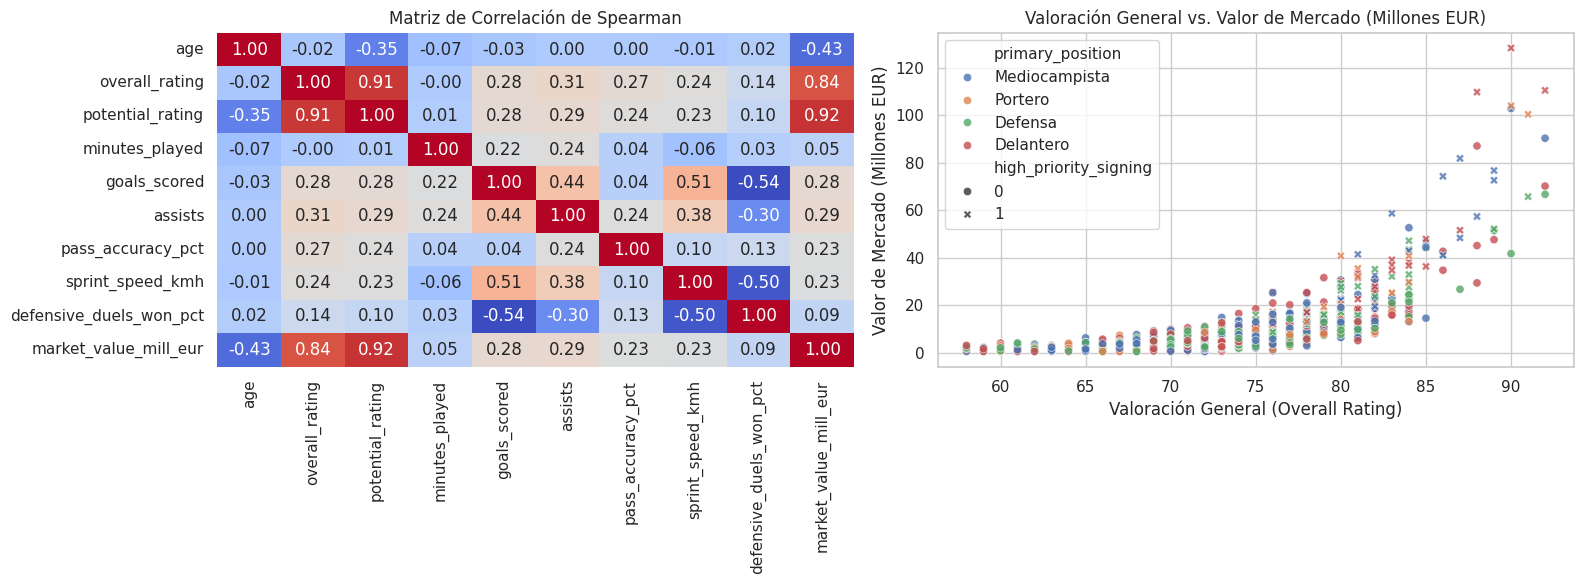

Prueba Chi-Cuadrado (Posición vs. Fichaje Prioritario): Chi2 = 22.49, p-valor = 5.1646e-05, gl = 3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz de correlación de Spearman (robusta ante relaciones monotónicas no lineales)
corr_matrix = df[num_cols].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0], cbar=False)
axes[0].set_title("Matriz de Correlación de Spearman")

# Scatter plot multivariable
sns.scatterplot(
    data=df, x='overall_rating', y='market_value_mill_eur',
    hue='primary_position', style='high_priority_signing', alpha=0.8, ax=axes[1]
)
axes[1].set_title("Valoración General vs. Valor de Mercado (Millones EUR)")
axes[1].set_xlabel("Valoración General (Overall Rating)")
axes[1].set_ylabel("Valor de Mercado (Millones EUR)")
plt.tight_layout()
plt.show()

# Prueba de independencia Chi-Cuadrado entre posición y fichaje prioritario
contingency_pos = pd.crosstab(df['primary_position'], df['high_priority_signing'])
chi2_val, p_val, dof, _ = chi2_contingency(contingency_pos)
print(f"Prueba Chi-Cuadrado (Posición vs. Fichaje Prioritario): Chi2 = {chi2_val:.2f}, p-valor = {p_val:.4e}, gl = {dof}")

## FASE 2: Preprocesamiento, Ingeniería de variables y modelo base (Baseline)

### 1. Diagnóstico del mecanismo de datos faltantes e imputación
Antes de imputar, se analiza la naturaleza de las ausencias en `sprint_speed_kmh` (4.50%) y `pass_accuracy_pct` (3.17%). Los registros faltantes se concentran en jugadores con menor cantidad de minutos disputados en cancha, donde los sistemas ópticos de telemetría no registran muestras suficientes. Por tanto, el mecanismo corresponde a **MAR (*Missing At Random*)**, ya que la probabilidad de ausencia depende de otras variables observadas (`minutes_played` y `primary_position`) y no del valor oculto en sí mismo.
* **Decisión técnica:** Se utiliza `KNNImputer(n_neighbors=5)` dentro de un `Pipeline` ajustado únicamente sobre el conjunto de entrenamiento, imputando cada jugador a partir de los 5 futbolistas más similares en edad, posición y rendimiento.

### 2. Tratamiento de valores atípicos (*Outliers*)
En lugar de eliminar a los jugadores élite (lo que sesgaría el modelo al borrar a las estrellas reales del fútbol), se aplica **recorte por percentiles (*Winsorization* entre el percentil 1% y 99%)** en `market_value_mill_eur`, `goals_scored` y `assists` para amortiguar valores extremos sin perder observaciones.

### 3. Ingeniería de variables basadas en conocimiento del dominio
Se construyen **3 nuevas variables** con sentido futbolístico:
1. `goal_contributions_per_90`: Goles más asistencias producidos por cada 90 minutos jugados, estandarizando la productividad ofensiva sin importar si el jugador fue titular o suplente.
2. `development_margin`: Diferencia entre el potencial futuro (`potential_rating`) y el nivel actual (`overall_rating`), clave para detectar jóvenes promesas.
3. `tactical_efficiency_index`: Índice compuesto que pondera al 50% la precisión de pase y al 50% el éxito en duelos defensivos.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

df_clean = df.copy()

# 1. Tratamiento de Outliers mediante Winsorization (percentiles 1% y 99%)
for col in ['market_value_mill_eur', 'goals_scored', 'assists']:
    low_p, high_p = np.nanpercentile(df_clean[col], [1, 99])
    df_clean[col] = np.clip(df_clean[col], low_p, high_p)

# 2. Creación de variables derivadas del dominio futbolístico
df_clean['goal_contributions_per_90'] = np.round(
    (df_clean['goals_scored'] + df_clean['assists']) / (df_clean['minutes_played'] / 90.0), 3
)
df_clean['development_margin'] = df_clean['potential_rating'] - df_clean['overall_rating']
df_clean['tactical_efficiency_index'] = np.round(
    0.5 * df_clean['pass_accuracy_pct'].fillna(df_clean['pass_accuracy_pct'].median()) +
    0.5 * df_clean['defensive_duels_won_pct'], 2
)

feature_cols_num = ['age', 'overall_rating', 'potential_rating', 'minutes_played', 'goals_scored',
                    'assists', 'pass_accuracy_pct', 'sprint_speed_kmh', 'defensive_duels_won_pct',
                    'goal_contributions_per_90', 'development_margin', 'tactical_efficiency_index']
feature_cols_nom = ['primary_position', 'league_name', 'preferred_foot']
feature_cols_ord = ['international_reputation']

X = df_clean[feature_cols_num + feature_cols_nom + feature_cols_ord]
y_reg = df_clean['market_value_mill_eur']
y_clf = df_clean['high_priority_signing']

# 3. Partición estratificada: 70% Entrenamiento (840), 15% Validación (180), 15% Prueba (180)
X_train, X_temp, y_reg_train, y_reg_temp, y_clf_train, y_clf_temp = train_test_split(
    X, y_reg, y_clf, test_size=0.30, random_state=42, stratify=y_clf
)
X_val, X_test, y_reg_val, y_reg_test, y_clf_val, y_clf_test = train_test_split(
    X_temp, y_reg_temp, y_clf_temp, test_size=0.50, random_state=42, stratify=y_clf_temp
)

# 4. Transformador de columnas libre de fuga de datos (fit exclusivamente en X_train)
num_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', RobustScaler())
])
nom_pipeline = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
ord_pipeline = OrdinalEncoder(categories=[['1 - Local', '2 - Continental', '3 - Internacional', '4 - Clase Mundial']])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, feature_cols_num),
    ('nom', nom_pipeline, feature_cols_nom),
    ('ord', ord_pipeline, feature_cols_ord)
])

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# 5. Entrenamiento y evaluación de modelos base (Baseline)
# Regresión Base: Regresión Lineal Ordinaria
baseline_reg = LinearRegression().fit(X_train_proc, y_reg_train)
pred_base_reg = baseline_reg.predict(X_test_proc)

# Clasificación base: Regresión logística con manejo de desbalance de clases (class_weight='balanced')
baseline_clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42).fit(X_train_proc, y_clf_train)
pred_base_clf = baseline_clf.predict(X_test_proc)
prob_base_clf = baseline_clf.predict_proba(X_test_proc)[:, 1]

print("=== LÍNEA BASE (BASELINE) EN CONJUNTO DE PRUEBA ===")
print(f"[Regresión Lineal Base]    R2: {r2_score(y_reg_test, pred_base_reg):.4f} | RMSE: {np.sqrt(mean_squared_error(y_reg_test, pred_base_reg)):.4f} M€ | MAE: {mean_absolute_error(y_reg_test, pred_base_reg):.4f} M€")
print(f"[Regresión Logística Base] Accuracy: {accuracy_score(y_clf_test, pred_base_clf):.4f} | Precision: {precision_score(y_clf_test, pred_base_clf):.4f} | Recall: {recall_score(y_clf_test, pred_base_clf):.4f} | F1: {f1_score(y_clf_test, pred_base_clf):.4f} | AUC-ROC: {roc_auc_score(y_clf_test, prob_base_clf):.4f}")

=== LÍNEA BASE (BASELINE) EN CONJUNTO DE PRUEBA ===
[Regresión Lineal Base]    R2: 0.6502 | RMSE: 6.3513 M€ | MAE: 4.1364 M€
[Regresión Logística Base] Accuracy: 0.9056 | Precision: 0.5405 | Recall: 1.0000 | F1: 0.7018 | AUC-ROC: 0.9828


## FASE 3: Modelado avanzado, Clustering, Red Neuronal en PyTorch e Interpretabilidad (SHAP)

En esta etapa se entrena, se optimiza mediante Validación Cruzada (`GridSearchCV` de 5 pliegues) y comparamos cuatro bloques analíticos:
1. **Regresión multivariable y ensambles:** Regresión Lineal Regularizada (`Ridge`), `RandomForestRegressor` y `GradientBoostingRegressor`.
2. **Deep Learning en PyTorch:** Diseño y entrenamiento de un **Perceptrón Multicapa (MLP)** de 3 capas con activaciones `ReLU`, regularización `Dropout(0.15)` y optimizador `Adam`, graficando la evolución de su función de pérdida (*MSE Loss*) en entrenamiento y validación.
3. **Clasificación supervisada:** Comparación entre `RandomForestClassifier` y `GradientBoostingClassifier` frente al modelo base.
4. **Clustering no supervisado:** Segmentación táctica con **K-Means** (seleccionando $K=4$ mediante el Método del Codo y el Coeficiente de Silueta) contrastado con **Clustering Jerárquico Aglomerativo**.
5. **Interpretabilidad con SHAP:** Explicación del impacto de cada variable sobre la predicción del valor de mercado.

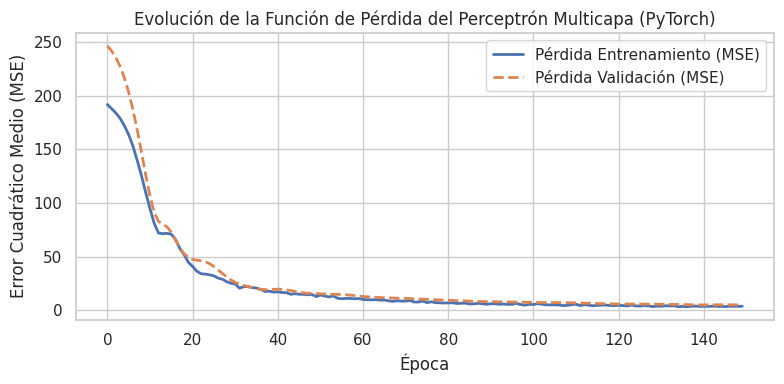

,Modelo de Regresión,R2,RMSE (M€),MAE (M€)
0,Baseline: Regresión Lineal Simple/Múltiple,0.6502,6.3513,4.1364
1,Regresión Lineal Regularizada (Ridge CV),0.6533,6.3231,4.0362
2,Random Forest Regressor (CV),0.9387,2.6587,1.7499
3,Perceptrón Multicapa (MLP en PyTorch),0.9544,2.2920,1.5487
4,Gradient Boosting Regressor (CV),0.9663,1.9724,1.3731


In [9]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import torch
import torch.nn as nn
import torch.optim as optim
import shap

# 1. Búsqueda de hiperparámetros con validación cruzada (5-Fold Cross-Validation)
ridge_cv = GridSearchCV(Ridge(), {'alpha': [0.1, 1.0, 10.0, 50.0]}, cv=5, scoring='r2').fit(X_train_proc, y_reg_train)
rf_reg_cv = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {'n_estimators': [100, 200], 'max_depth': [8, 10]},
    cv=5, scoring='r2', n_jobs=-1
).fit(X_train_proc, y_reg_train)
gb_reg_cv = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {'n_estimators': [150, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 4]},
    cv=5, scoring='r2', n_jobs=-1
).fit(X_train_proc, y_reg_train)

# 2. Diseño y Entrenamiento del Perceptrón Multicapa (MLP) en PyTorch
torch.manual_seed(42)
X_tr_t = torch.tensor(X_train_proc, dtype=torch.float32)
y_tr_t = torch.tensor(y_reg_train.values, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val_proc, dtype=torch.float32)
y_val_t = torch.tensor(y_reg_val.values, dtype=torch.float32).unsqueeze(1)
X_te_t = torch.tensor(X_test_proc, dtype=torch.float32)

mlp_model = nn.Sequential(
    nn.Linear(X_train_proc.shape[1], 64),
    nn.ReLU(),
    nn.Dropout(0.15),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
optimizer = optim.Adam(mlp_model.parameters(), lr=0.01, weight_decay=1e-4)
criterion = nn.MSELoss()

train_losses, val_losses = [], []
for epoch in range(150):
    mlp_model.train()
    optimizer.zero_grad()
    loss_tr = criterion(mlp_model(X_tr_t), y_tr_t)
    loss_tr.backward()
    optimizer.step()
    train_losses.append(loss_tr.item())

    mlp_model.eval()
    with torch.no_grad():
        loss_v = criterion(mlp_model(X_val_t), y_val_t)
        val_losses.append(loss_v.item())

with torch.no_grad():
    pred_mlp = mlp_model(X_te_t).squeeze().numpy()

# Gráfica de la función de pérdida en PyTorch (Entrenamiento vs. Validación)
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label='Pérdida Entrenamiento (MSE)', linewidth=2)
plt.plot(val_losses, label='Pérdida Validación (MSE)', linestyle='--', linewidth=2)
plt.title('Evolución de la Función de Pérdida del Perceptrón Multicapa (PyTorch)')
plt.xlabel('Época')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.legend()
plt.tight_layout()
plt.show()

# Tabla comparativa de métricas de regresión en el conjunto de Prueba
reg_results = []
for name, preds in [
    ('Baseline: Regresión Lineal Simple/Múltiple', pred_base_reg),
    ('Regresión Lineal Regularizada (Ridge CV)', ridge_cv.predict(X_test_proc)),
    ('Random Forest Regressor (CV)', rf_reg_cv.predict(X_test_proc)),
    ('Perceptrón Multicapa (MLP en PyTorch)', pred_mlp),
    ('Gradient Boosting Regressor (CV)', gb_reg_cv.predict(X_test_proc))
]:
    reg_results.append({
        'Modelo de Regresión': name,
        'R2': round(r2_score(y_reg_test, preds), 4),
        'RMSE (M€)': round(np.sqrt(mean_squared_error(y_reg_test, preds)), 4),
        'MAE (M€)': round(mean_absolute_error(y_reg_test, preds), 4)
    })
display(pd.DataFrame(reg_results))

=== EVALUACIÓN COMPARATIVA DE CLASIFICACIÓN ===


,Modelo de Clasificación,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Baseline: Regresión Logística,0.9056,0.5405,1.0,0.7018,0.9828
1,Random Forest Classifier,0.9944,0.9524,1.0,0.9756,0.9994
2,Gradient Boosting Classifier,0.9889,0.9091,1.0,0.9524,1.0000


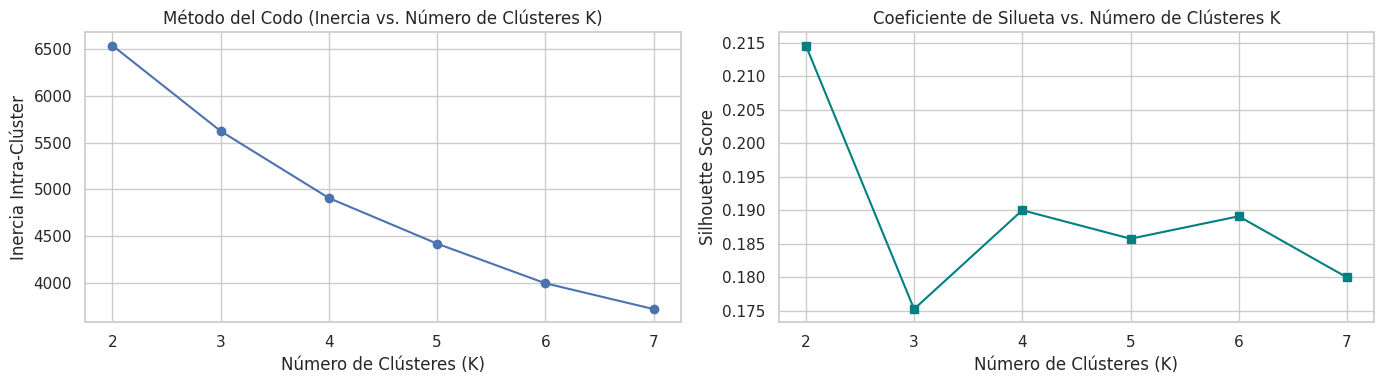

Silhouette Score K-Means (K=4): 0.1900
Silhouette Score Jerárquico Aglomerativo (K=4): 0.1681

=== PERFIL NUMÉRICO PROMEDIO DE LOS 4 CLÚSTERES DESCUBIERTOS ===


,age,overall_rating,goals_scored,assists,pass_accuracy_pct,sprint_speed_kmh,defensive_duels_won_pct,market_value_mill_eur
cluster_tactico,,,,,,,,
0,26.94,68.97,0.77,0.63,84.48,30.57,62.75,4.26
1,26.88,75.08,4.76,2.02,80.57,33.03,44.37,11.79
2,27.28,72.74,0.07,0.12,76.30,25.50,74.67,8.46
3,27.05,77.95,1.71,2.71,88.63,31.31,65.88,15.11


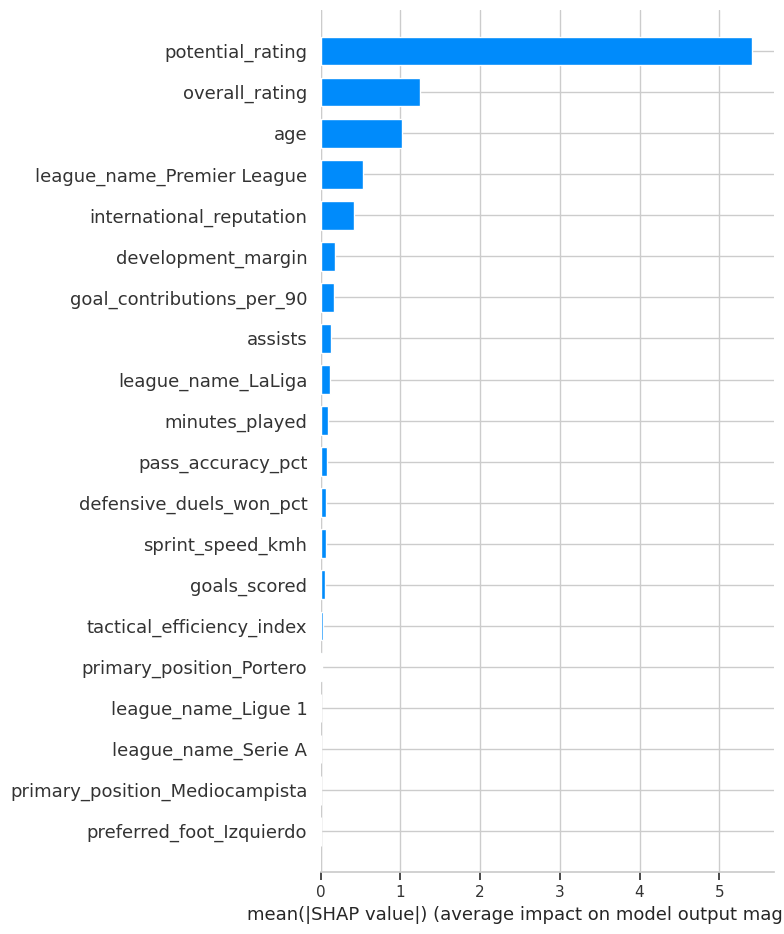

In [10]:
from sklearn.preprocessing import StandardScaler

# 1. Comparación de modelos de clasificación
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42).fit(X_train_proc, y_clf_train)
gb_clf = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train_proc, y_clf_train)

clf_results = []
for name, model in [
    ('Baseline: Regresión Logística', baseline_clf),
    ('Random Forest Classifier', rf_clf),
    ('Gradient Boosting Classifier', gb_clf)
]:
    p = model.predict(X_test_proc)
    pr = model.predict_proba(X_test_proc)[:, 1]
    clf_results.append({
        'Modelo de Clasificación': name,
        'Accuracy': round(accuracy_score(y_clf_test, p), 4),
        'Precision': round(precision_score(y_clf_test, p), 4),
        'Recall': round(recall_score(y_clf_test, p), 4),
        'F1-Score': round(f1_score(y_clf_test, p), 4),
        'AUC-ROC': round(roc_auc_score(y_clf_test, pr), 4)
    })
print("=== EVALUACIÓN COMPARATIVA DE CLASIFICACIÓN ===")
display(pd.DataFrame(clf_results))

# 2. Aprendizaje no supervisado: K-Means (Codo y Silueta) + Clustering Jerárquico Aglomerativo
cluster_vars = ['age', 'overall_rating', 'goals_scored', 'assists', 'pass_accuracy_pct', 'sprint_speed_kmh', 'defensive_duels_won_pct']
X_clust = StandardScaler().fit_transform(KNNImputer(n_neighbors=5).fit_transform(df_clean[cluster_vars]))

inertias, silhouettes = [], []
K_range = range(2, 8)
for k in K_range:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_clust)
    inertias.append(km_temp.inertia_)
    silhouettes.append(silhouette_score(X_clust, km_temp.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(list(K_range), inertias, marker='o')
ax[0].set_title('Método del Codo (Inercia vs. Número de Clústeres K)')
ax[0].set_xlabel('Número de Clústeres (K)')
ax[0].set_ylabel('Inercia Intra-Clúster')

ax[1].plot(list(K_range), silhouettes, marker='s', color='teal')
ax[1].set_title('Coeficiente de Silueta vs. Número de Clústeres K')
ax[1].set_xlabel('Número de Clústeres (K)')
ax[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

kmeans_opt = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_clust)
agg_opt = AgglomerativeClustering(n_clusters=4).fit(X_clust)
print(f"Silhouette Score K-Means (K=4): {silhouette_score(X_clust, kmeans_opt.labels_):.4f}")
print(f"Silhouette Score Jerárquico Aglomerativo (K=4): {silhouette_score(X_clust, agg_opt.labels_):.4f}")

df_clean['cluster_tactico'] = kmeans_opt.labels_
print("\n=== PERFIL NUMÉRICO PROMEDIO DE LOS 4 CLÚSTERES DESCUBIERTOS ===")
display(df_clean.groupby('cluster_tactico')[cluster_vars + ['market_value_mill_eur']].mean().round(2))

# 3. Análisis de interpretabilidad con SHAP
feature_names_all = (
    feature_cols_num +
    list(preprocessor.named_transformers_['nom'].get_feature_names_out(feature_cols_nom)) +
    feature_cols_ord
)
explainer = shap.TreeExplainer(gb_reg_cv.best_estimator_)
shap_values = explainer.shap_values(X_test_proc)
shap.summary_plot(shap_values, X_test_proc, feature_names=feature_names_all, plot_type="bar")